# E0.3b — Walk candidate, continuation and exit study

**Research baseline.** Keep E0.2 thresholds frozen. Forward horizons measured in *native candles*, not hours. Labels use future closes and are never input features. Close-to-close returns are descriptive, **not executable P&L**. Walk snapshots overlap and must not be regarded as independent.

Requires `bars`: original 5-minute OHLCV indexed by candle **open** time, with sufficient warm-up before the start date.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from walk_states import bollinger_from_5m, detect_walk_states
from e03_analysis import (align_to_5m, occupancy, next_walk_probabilities,
                          cross_overlap, conditional_lift, plot_pair)

import requests
from pathlib import Path
import json

START, END = "2025-01-01", "2026-01-01"
TIMEFRAMES = {"4H":"4h", "1H":"1h", "15m":"15min", "5m":"5min"}
PARAMS = dict(near=0.15, confirm_bars=3, exit_bars=2, slope_bars=3)

NOV_START = "2025-11-13"
NOV_END = "2025-11-23"

CONFIGS = {"1D":"1D", "1H":"1h", "15m":"15min", "5m":"5min"}
WINDOW = 20
NEAR = 0.15
CONFIRM_BARS = 3
EXIT_BARS = 2
SLOPE_BARS = 3

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

# Paste the verified 5m OHLCV loader from 02_price_features.ipynb or E03 here.
# TODO: paste verified 5-minute data loading code from 02_price_features.ipynb
all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()
assert "bars" in globals(), "Load your existing 5m OHLCV dataframe as bars first"
assert "bars" in globals(), "First load your verified 5-minute OHLCV dataframe as `bars`."
assert {"open","high","low","close","volume"}.issubset(bars.columns)
print('Rows:',len(bars),'Range:',bars.index.min(),bars.index.max())

Expected candles: 105984
Loaded 105,984 candles
Download/cache loading complete.
Rows: 105984 Range: 2024-12-30 00:00:00+00:00 2026-01-01 23:55:00+00:00


In [5]:
import pandas as pd
from walk_states import bollinger_from_5m
from e03a_trace import audit_walk_states
from e03b_analysis import event_table, walk_survival, summaries

# Import bars from your verified E03 loader here.
assert "bars" in globals(), "Load the original 5m OHLCV dataframe first"


In [6]:
START, END = "2025-01-01", "2026-01-01"
TF = {"4H": "4h", "1H": "1h", "15m": "15min", "5m": "5min"}
CONFIG = dict(near=.15, confirm_bars=3, exit_bars=2, slope_bars=3)
RET_HORIZONS = (1,3,6,12,24)
SURVIVAL_HORIZONS = (1,3,6)
runs = {}
for name, step in TF.items():
    bb = bollinger_from_5m(bars, START, END, resolution=step, window=20, num_std=2.)
    states, transitions, trace, confirmations = audit_walk_states(bb, **CONFIG)
    events = event_table(states, trace, horizons=RET_HORIZONS)
    survival = walk_survival(states, horizons=SURVIVAL_HORIZONS)
    ret, hazard = summaries(events, survival, horizons=RET_HORIZONS)
    runs[name] = dict(states=states, trace=trace, events=events, survival=survival, returns=ret, survival_stats=hazard)
    print(name, 'candles',len(states),'events',len(events),'active snapshots',len(survival))


4H candles 2190 events 314 active snapshots 368
1H candles 8760 events 1349 active snapshots 1707
15m candles 35040 events 5566 active snapshots 6703
5m candles 105120 events 17287 active snapshots 20464


## A. Direction-adjusted returns after detection, confirmation and exit

Positive return means movement **in the original walk direction**, including for `DISTANCE_EXIT`. These results compare event origins but do not establish trading profitability. A one-bar return from an event closing price is not necessarily fillable.

In [7]:
for tf, run in runs.items():
    print('\n',tf)
    display(run['returns'])



 4H


ret_1b_pct                     ret_3b_pct            \
                              count    median      mean      count    median   
event         direction                                                        
CANDIDATE     LOWER_WALK         77  0.093462  0.136783         77 -0.226303   
              UPPER_WALK         87 -0.106820 -0.206036         87 -0.320244   
CONFIRMED     LOWER_WALK         39 -0.183160 -0.216703         39 -0.204967   
              UPPER_WALK         36  0.025094  0.194546         36 -0.051003   
DISTANCE_EXIT LOWER_WALK         39  0.106016  0.187791         39  0.124159   
              UPPER_WALK         36 -0.123282 -0.152778         36  0.118448   

                                   ret_6b_pct                     ret_12b_pct  \
                              mean      count    median      mean       count   
event         direction                                                         
CANDIDATE     LOWER_WALK -0.138408         77 -0.098273  0.015340          77   
              UPPER_WALK -0.357815         87 -0.513754 -0.496157          86   
CONFIRMED     LOWER_WALK -0.125895         39 -0.087724  0.147265          39   
              UPPER_WALK -0.030508         36  0.417029  0.218999          36   
DISTANCE_EXIT LOWER_WALK  0.185364         39  0.047111  0.204400          39   
              UPPER_WALK  0.236964         36 -0.000526  0.066439          36   

                                             ret_24b_pct                      
                            median      mean       count    median      mean  
event         direction                                                       
CANDIDATE     LOWER_WALK -0.206945  0.136046          77 -0.238563 -0.180058  
              UPPER_WALK -0.495309 -0.388279          85 -0.494175 -0.141652  
CONFIRMED     LOWER_WALK -0.508127 -0.665923          39 -1.757969 -0.967180  
              UPPER_WALK -0.041722  0.357555          36 -0.775053 -0.090071  
DISTANCE_EXIT LOWER_WALK -0.620431 -0.503087          39 -0.475588 -0.603596  
              UPPER_WALK  0.807746  0.474608          36 -0.070985 -0.103491


 1H


ret_1b_pct                     ret_3b_pct            \
                              count    median      mean      count    median   
event         direction                                                        
CANDIDATE     LOWER_WALK        344 -0.032763  0.005087        344 -0.049067   
              UPPER_WALK        353 -0.021396  0.043948        353 -0.057807   
CONFIRMED     LOWER_WALK        158 -0.024705  0.060581        158 -0.037342   
              UPPER_WALK        168 -0.011747 -0.039696        168 -0.018125   
DISTANCE_EXIT LOWER_WALK        158 -0.011063 -0.032295        157 -0.049780   
              UPPER_WALK        168  0.008572  0.010573        168 -0.044773   

                                   ret_6b_pct                     ret_12b_pct  \
                              mean      count    median      mean       count   
event         direction                                                         
CANDIDATE     LOWER_WALK  0.054362        344 -0.042876  0.056479         343   
              UPPER_WALK  0.027015        353 -0.062409  0.028926         352   
CONFIRMED     LOWER_WALK  0.093812        158 -0.038826  0.084452         157   
              UPPER_WALK -0.045972        168 -0.062518 -0.106328         168   
DISTANCE_EXIT LOWER_WALK -0.068704        157 -0.120877 -0.045028         157   
              UPPER_WALK -0.046076        168 -0.050872 -0.064865         168   

                                             ret_24b_pct                      
                            median      mean       count    median      mean  
event         direction                                                       
CANDIDATE     LOWER_WALK -0.082448  0.001824         343 -0.144262 -0.121421  
              UPPER_WALK -0.068991 -0.023443         351 -0.063687 -0.053773  
CONFIRMED     LOWER_WALK -0.199624 -0.142407         157 -0.255382 -0.107854  
              UPPER_WALK -0.101811 -0.145572         168 -0.163030 -0.176244  
DISTANCE_EXIT LOWER_WALK -0.404335 -0.282041         157 -0.123745 -0.042079  
              UPPER_WALK -0.031694 -0.033726         168 -0.036375 -0.028375


 15m


ret_1b_pct                     ret_3b_pct            \
                              count    median      mean      count    median   
event         direction                                                        
CANDIDATE     LOWER_WALK       1498 -0.031894 -0.017937       1498 -0.025344   
              UPPER_WALK       1564 -0.024454 -0.010100       1564 -0.011231   
CONFIRMED     LOWER_WALK        612 -0.024940 -0.026592        612 -0.018544   
              UPPER_WALK        640 -0.014596  0.000247        640 -0.022609   
DISTANCE_EXIT LOWER_WALK        612  0.001431  0.010945        612 -0.000418   
              UPPER_WALK        640  0.003744 -0.009967        640 -0.005925   

                                   ret_6b_pct                     ret_12b_pct  \
                              mean      count    median      mean       count   
event         direction                                                         
CANDIDATE     LOWER_WALK -0.016036       1498 -0.037708 -0.016473        1498   
              UPPER_WALK -0.000241       1564 -0.006625  0.023252        1564   
CONFIRMED     LOWER_WALK -0.036351        612 -0.036483  0.009508         612   
              UPPER_WALK -0.000189        640 -0.011543  0.014842         640   
DISTANCE_EXIT LOWER_WALK  0.026779        612 -0.007451 -0.000774         612   
              UPPER_WALK -0.001637        640 -0.018290 -0.031997         640   

                                             ret_24b_pct                      
                            median      mean       count    median      mean  
event         direction                                                       
CANDIDATE     LOWER_WALK -0.077264 -0.027938        1497 -0.050853 -0.025549  
              UPPER_WALK -0.025315  0.014851        1564 -0.024219  0.023806  
CONFIRMED     LOWER_WALK -0.049436  0.005528         612 -0.044051 -0.016237  
              UPPER_WALK -0.019235  0.007913         640 -0.037331 -0.032488  
DISTANCE_EXIT LOWER_WALK -0.030675  0.018355         612 -0.065982 -0.027472  
              UPPER_WALK -0.012684  0.010450         640 -0.029260 -0.026566


 5m


ret_1b_pct                     ret_3b_pct            \
                              count    median      mean      count    median   
event         direction                                                        
CANDIDATE     LOWER_WALK       4599 -0.005143  0.000739       4599 -0.005227   
              UPPER_WALK       4608 -0.004074  0.000649       4608 -0.009338   
CONFIRMED     LOWER_WALK       2002 -0.003241  0.002639       2002 -0.015821   
              UPPER_WALK       2038 -0.005094 -0.002521       2038 -0.016665   
DISTANCE_EXIT LOWER_WALK       2002 -0.003036 -0.001449       2002 -0.004527   
              UPPER_WALK       2038  0.000000 -0.000025       2038  0.002670   

                                   ret_6b_pct                     ret_12b_pct  \
                              mean      count    median      mean       count   
event         direction                                                         
CANDIDATE     LOWER_WALK -0.001352       4599 -0.013223  0.001443        4598   
              UPPER_WALK -0.002598       4608 -0.012749 -0.007972        4608   
CONFIRMED     LOWER_WALK  0.005776       2002 -0.023198 -0.000684        2001   
              UPPER_WALK -0.008159       2038 -0.016535 -0.017835        2038   
DISTANCE_EXIT LOWER_WALK -0.009238       2002 -0.003520 -0.000149        2001   
              UPPER_WALK  0.003713       2038 -0.000971  0.000120        2038   

                                             ret_24b_pct                      
                            median      mean       count    median      mean  
event         direction                                                       
CANDIDATE     LOWER_WALK -0.016466  0.002998        4597 -0.029248  0.003691  
              UPPER_WALK -0.017108 -0.014423        4608 -0.010736 -0.004487  
CONFIRMED     LOWER_WALK -0.016065  0.003818        2001 -0.019094  0.015751  
              UPPER_WALK -0.022098 -0.009067        2038 -0.011595 -0.004996  
DISTANCE_EXIT LOWER_WALK -0.003902 -0.002744        2001 -0.010430  0.003929  
              UPPER_WALK  0.003120  0.003354        2038 -0.007803  0.000687

## B. Remaining walk survival by confirmed walk age

The survival statistic measures whether the **same confirmed walk episode** remains active at a future bar. It is not a price return, and a gap/end-of-data observation is censored. The age is measured from walk **confirmation** (`0` at confirmation), not first approach. Multiple snapshots per episode are dependent.

In [8]:
for tf, run in runs.items():
    print('\n',tf)
    display(run['survival_stats'])



 4H


survives_1b           survives_3b           survives_6b  \
                         count      mean       count      mean       count   
direction  age_bin                                                           
LOWER_WALK 0-2             107  0.869159         107  0.504673         107   
           3-5              54  0.722222          54  0.407407          54   
           6-11             24  0.583333          24  0.083333          24   
UPPER_WALK 0-2              99  0.858586          99  0.505051          99   
           3-5              50      0.76          50      0.42          50   
           6-11             30  0.733333          30  0.433333          30   
           12+               4       0.5           4       0.0           4   

                              
                        mean  
direction  age_bin            
LOWER_WALK 0-2      0.205607  
           3-5      0.037037  
           6-11          0.0  
UPPER_WALK 0-2      0.212121  
           3-5          0.18  
           6-11     0.133333  
           12+           0.0


 1H


survives_1b           survives_3b           survives_6b  \
                         count      mean       count      mean       count   
direction  age_bin                                                           
LOWER_WALK 0-2             443  0.882619         443  0.553047         441   
           3-5             245  0.742857         244  0.389344         243   
           6-11            128  0.703125         128  0.351562         128   
           12+              17  0.705882          17  0.294118          17   
UPPER_WALK 0-2             468  0.880342         468  0.547009         468   
           3-5             256  0.730469         256  0.394531         256   
           6-11            131  0.709924         131  0.305344         131   
           12+              19  0.736842          19  0.473684          19   

                              
                        mean  
direction  age_bin            
LOWER_WALK 0-2       0.21542  
           3-5      0.135802  
           6-11     0.117188  
           12+      0.117647  
UPPER_WALK 0-2      0.215812  
           3-5      0.117188  
           6-11     0.099237  
           12+      0.315789


 15m


survives_1b           survives_3b           survives_6b  \
                         count      mean       count      mean       count   
direction  age_bin                                                           
LOWER_WALK 0-2            1710  0.867251        1710  0.543275        1710   
           3-5             929  0.780409         929  0.468245         929   
           6-11            608  0.748355         608  0.393092         608   
           12+             102   0.72549         102  0.352941         102   
UPPER_WALK 0-2            1785  0.864426        1785   0.52605        1785   
           3-5             939  0.781683         939  0.444089         939   
           6-11            560  0.692857         560  0.333929         560   
           12+              70       0.7          70  0.371429          70   

                              
                        mean  
direction  age_bin            
LOWER_WALK 0-2      0.254386  
           3-5      0.186222  
           6-11     0.152961  
           12+      0.088235  
UPPER_WALK 0-2      0.233613  
           3-5       0.15229  
           6-11     0.108929  
           12+      0.128571


 5m


survives_1b           survives_3b           survives_6b  \
                         count      mean       count      mean       count   
direction  age_bin                                                           
LOWER_WALK 0-2            5556  0.858891        5556  0.514579        5556   
           3-5            2859  0.760056        2859   0.43092        2859   
           6-11           1706   0.73857        1706  0.396835        1706   
           12+             359  0.760446         359   0.43454         359   
UPPER_WALK 0-2            5636  0.855039        5636  0.495742        5636   
           3-5            2794  0.731568        2794  0.368289        2794   
           6-11           1417  0.704305        1417   0.34439        1417   
           12+             137  0.620438         137  0.270073         137   

                              
                        mean  
direction  age_bin            
LOWER_WALK 0-2      0.221742  
           3-5      0.165792  
           6-11     0.171161  
           12+       0.18663  
UPPER_WALK 0-2      0.182576  
           3-5      0.138869  
           6-11     0.091743  
           12+      0.051095

## C. Visual inspection of walk age and continuation

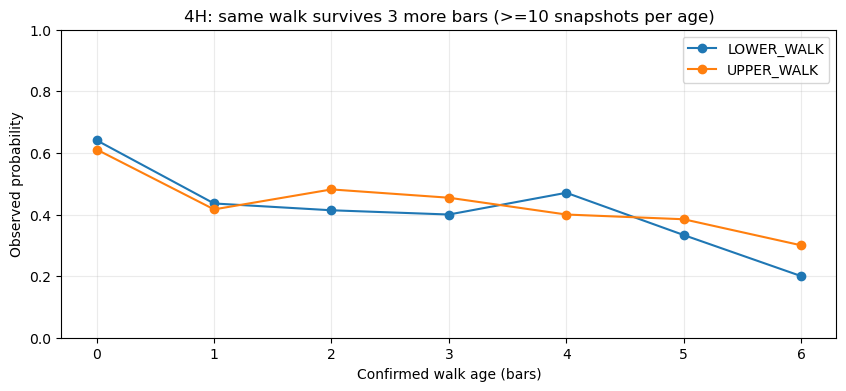

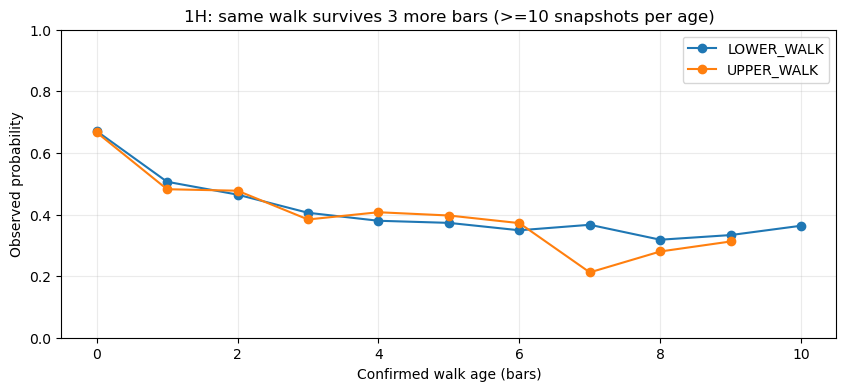

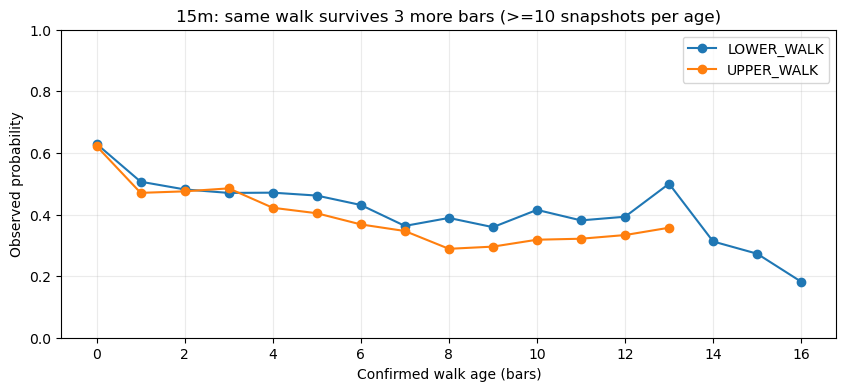

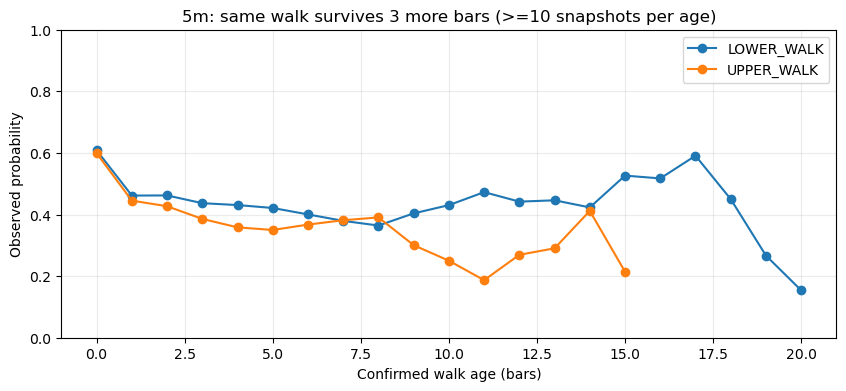

In [9]:
import matplotlib.pyplot as plt
for tf,run in runs.items():
    x=run['survival'].copy()
    if x.empty: continue
    fig, ax=plt.subplots(figsize=(10,4))
    for direction, group in x.groupby('direction'):
        y=group.groupby('age_bars')['survives_3b'].agg(['mean','count'])
        y=y.loc[y['count']>=10]
        if len(y): ax.plot(y.index,y['mean'],marker='o',label=direction)
    ax.set(title=f'{tf}: same walk survives 3 more bars (>=10 snapshots per age)',xlabel='Confirmed walk age (bars)',ylabel='Observed probability',ylim=(0,1))
    ax.legend(); ax.grid(alpha=.25);plt.show()


## Interpretation limits and next gate

1. The candidate population includes first qualifying candle sequences, including sequences that never confirm. Confirmed/exit samples overlap with earlier candidates.
2. Window-end labels are censored; do not count them as failures.
3. Estimates from overlapping candles are correlated. Follow with walk-cluster bootstrap and chronologically held-out testing.
4. Next increments: walk-episode outcomes, MFE/MAE and ATR-normalized barriers, confirmation opportunity cost, followed by band-width/compression and adaptive thresholds.
5. No optimization or live-trading claims should be made from these exploratory results.